# MarketLens Phase 3 — Model Comparison Notebook
## 3-Model Ablation Study: Does Event Intelligence Add Predictive Edge?

This notebook executes the full ML pipeline and visualises:
1. Dataset characteristics and target distribution
2. Chronological split timeline
3. Model performance comparison (Accuracy, F1, ROC-AUC)
4. Feature importances (Model C)
5. Abnormal return distribution analysis

**Strict constraint**: Zero look-ahead bias — chronological split only, no shuffle.

In [1]:
import sys
import os
import warnings

# Add project root to sys.path reliably (works whether started in root or notebooks/)
current_dir = os.path.abspath(os.getcwd())
if os.path.exists(os.path.join(current_dir, 'database')):
    PROJECT_ROOT = current_dir
elif os.path.exists(os.path.join(current_dir, '..', 'database')):
    PROJECT_ROOT = os.path.abspath(os.path.join(current_dir, '..'))
else:
    PROJECT_ROOT = r'c:\Users\gamin\Desktop\App_gen_ai'

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
try:
    from IPython.display import display
except ImportError:
    display = print

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
FIGSIZE = (14, 6)

print('Environment ready. Python:', sys.version.split()[0])
print('Project root:', PROJECT_ROOT)


Environment ready. Python: 3.12.9
Project root: c:\Users\gamin\Desktop\App_gen_ai


## 1. Build Event Matrix from PostgreSQL

In [2]:
import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s')

from database.connection import SessionLocal
from backend.ml.dataset_builder import build_event_matrix, _load_market_data, _load_index_data

print('Loading data from PostgreSQL...')
with SessionLocal() as session:
    event_df = build_event_matrix(session)
    mkt_df   = _load_market_data(session)
    idx_df   = _load_index_data(session)

print(f'\nRaw event matrix: {event_df.shape[0]} events x {event_df.shape[1]} columns')
display(event_df.head(3))

2026-10-01 01:00:48,947 [INFO] Loading market and index data...
2026-10-01 01:00:49,105 [INFO] Loaded 3410 market rows (5 tickers) | 677 index rows
2026-10-01 01:00:49,118 [INFO] Processing 96 ticker-linked events...


Loading data from PostgreSQL...


2026-10-01 01:00:49,609 [INFO] Event matrix: 25 rows built | 71 skipped (missing price/index data)



Raw event matrix: 25 events x 25 columns


,event_id,news_id,ticker,published_at,event_date,p0,p1,p3,p5,m0,...,ar_5,target_AR3_positive,event_type,gemini_sentiment,magnitude,surprise,finbert_positive,finbert_negative,finbert_neutral,summary
0,174,139,HDFCBANK,2026-09-22 09:22:00+05:30,2026-09-22 00:00:00+00:00,739.5,737.2500,735.6,None,23414.3008,...,None,1,MACRO_DATA,NEUTRAL,None,IN_LINE,0.538891,0.031189,0.429919,HDFC Bank's share price rises for two consecut...
1,172,35,INFY,2026-09-22 09:22:40+05:30,2026-09-22 00:00:00+00:00,1038.5,1020.5000,1000.2,None,23414.3008,...,None,0,MONETARY_POLICY,NEGATIVE,None,NaN,0.008998,0.969913,0.021088,Infosys shares slip amid headwinds in the info...
2,173,70,TCS,2026-09-22 09:22:39+05:30,2026-09-22 00:00:00+00:00,2128.7,2089.6001,2082.0,None,23414.3008,...,None,0,MONETARY_POLICY,NEGATIVE,None,NaN,0.013728,0.962863,0.023409,Shares of TCS dip amid group volatility.


## 2. Dataset Overview & Target Distribution

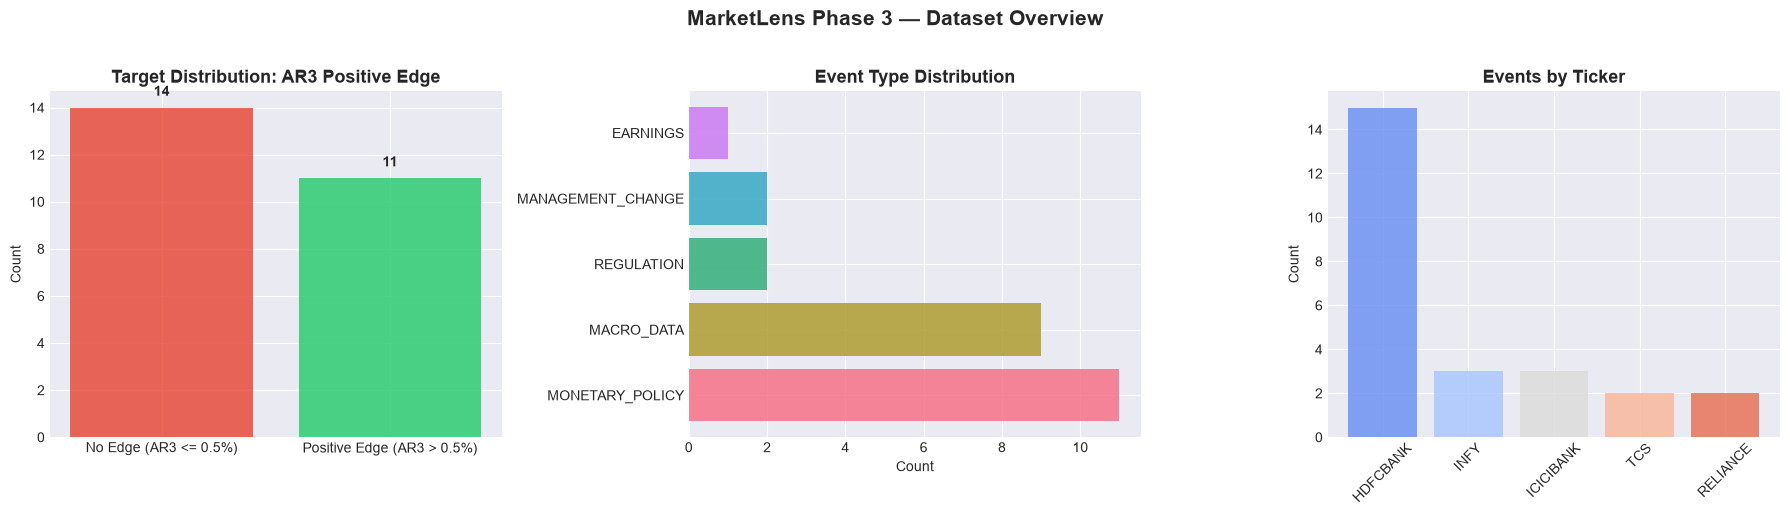


Abnormal Return (AR3) Statistics:
count    25.0000
mean     -0.0006
std       0.0080
min      -0.0252
25%      -0.0029
50%      -0.0019
75%       0.0064
max       0.0072
Name: ar_3, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Target distribution
target_counts = event_df['target_AR3_positive'].value_counts()
labels = ['No Edge (AR3 <= 0.5%)', 'Positive Edge (AR3 > 0.5%)']
colors = ['#e74c3c', '#2ecc71']
axes[0].bar(labels, [target_counts.get(0, 0), target_counts.get(1, 0)], color=colors, alpha=0.85)
axes[0].set_title('Target Distribution: AR3 Positive Edge', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
for i, v in enumerate([target_counts.get(0, 0), target_counts.get(1, 0)]):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

# Event type breakdown
et_counts = event_df['event_type'].value_counts()
axes[1].barh(et_counts.index, et_counts.values, color=sns.color_palette('husl', len(et_counts)), alpha=0.85)
axes[1].set_title('Event Type Distribution', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Count')

# Ticker breakdown
ticker_counts = event_df['ticker'].value_counts()
axes[2].bar(ticker_counts.index, ticker_counts.values, color=sns.color_palette('coolwarm', len(ticker_counts)), alpha=0.85)
axes[2].set_title('Events by Ticker', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Count')
axes[2].tick_params(axis='x', rotation=45)

plt.suptitle('MarketLens Phase 3 — Dataset Overview', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('dataset_overview.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nAbnormal Return (AR3) Statistics:')
print(event_df['ar_3'].describe().round(4))

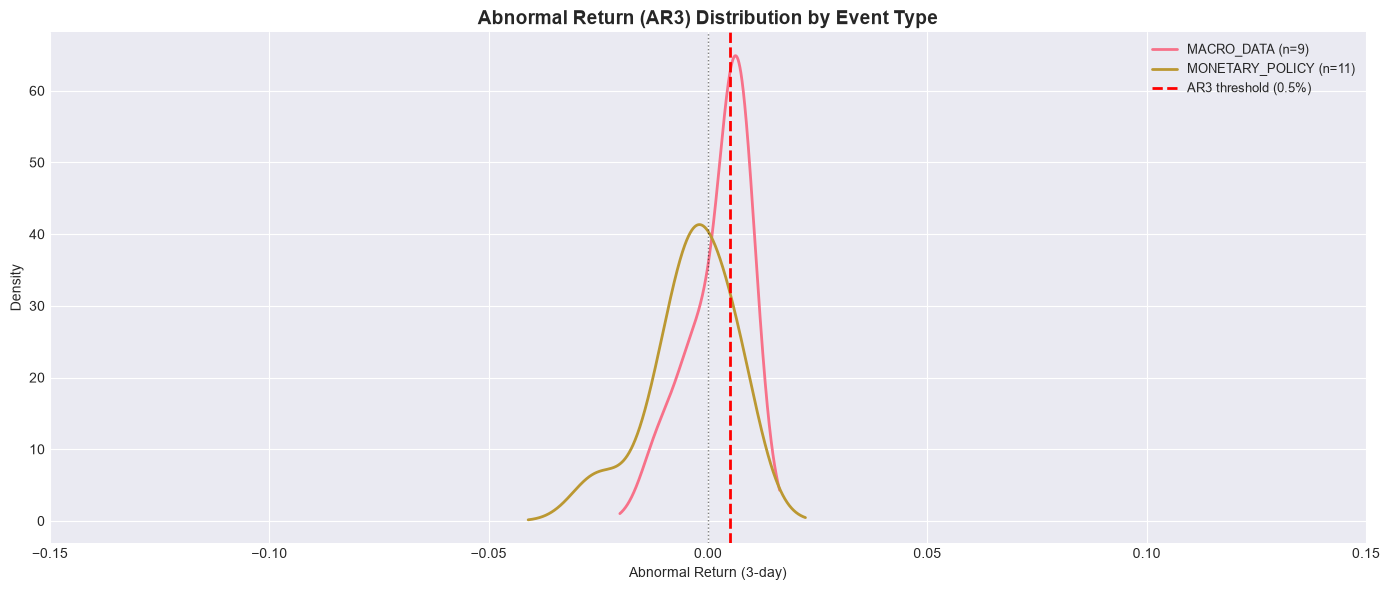

In [4]:
# AR distribution by event type
fig, ax = plt.subplots(figsize=FIGSIZE)
event_df_clean = event_df.dropna(subset=['ar_3'])

for et in event_df_clean['event_type'].unique():
    subset = event_df_clean[event_df_clean['event_type'] == et]['ar_3']
    if len(subset) > 2:
        subset.plot.kde(ax=ax, label=f'{et} (n={len(subset)})', linewidth=2)

ax.axvline(x=0.005, color='red', linestyle='--', linewidth=2, label='AR3 threshold (0.5%)')
ax.axvline(x=0, color='black', linestyle=':', linewidth=1, alpha=0.5)
ax.set_title('Abnormal Return (AR3) Distribution by Event Type', fontsize=14, fontweight='bold')
ax.set_xlabel('Abnormal Return (3-day)')
ax.set_ylabel('Density')
ax.legend(loc='upper right', fontsize=9)
ax.set_xlim(-0.15, 0.15)
plt.tight_layout()
plt.savefig('ar3_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Feature Engineering

In [5]:
from backend.ml.features import (
    build_features, 
    FEATURE_SET_A, FEATURE_SET_B, FEATURE_SET_C, TARGET_COL
)

print('Building feature matrix (technical + event features)...')
feature_df = build_features(event_df, mkt_df, idx_df)

print(f'Feature matrix: {feature_df.shape[0]} events x {feature_df.shape[1]} columns')
print(f'\nTarget distribution after feature engineering:')
print(feature_df[TARGET_COL].value_counts())

print(f'\nFeature sets:')
print(f'  Model A (Market Baseline):    {len(FEATURE_SET_A)} features')
print(f'  Model B (Market + Sentiment): {len(FEATURE_SET_B)} features')
print(f'  Model C (Event-Aware):        {len(FEATURE_SET_C)} features')

2026-10-01 01:00:51,504 [INFO] Computing technical features for 25 events...
2026-10-01 01:00:51,554 [INFO] Encoding event features...
2026-10-01 01:00:51,564 [INFO] Dropped 0 rows with NaN in critical features (25 -> 25 rows).


Building feature matrix (technical + event features)...
Feature matrix: 25 events x 42 columns

Target distribution after feature engineering:
target_AR3_positive
0    14
1    11
Name: count, dtype: int64

Feature sets:
  Model A (Market Baseline):    5 features
  Model B (Market + Sentiment): 8 features
  Model C (Event-Aware):        21 features


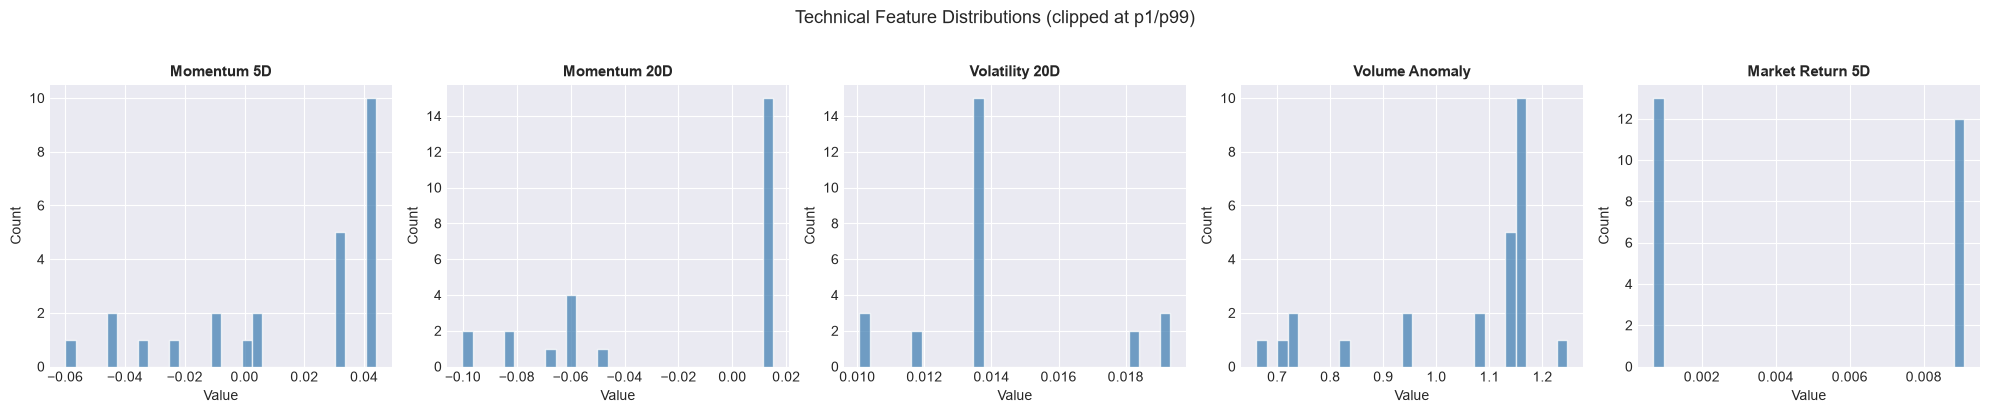

In [6]:
# Technical feature distributions
tech_feats = [f for f in FEATURE_SET_A if f in feature_df.columns]
n_feats = len(tech_feats)

fig, axes = plt.subplots(1, n_feats, figsize=(4*n_feats, 4))
if n_feats == 1:
    axes = [axes]

for ax, feat in zip(axes, tech_feats):
    data = feature_df[feat].dropna()
    # Clip extreme outliers for display
    q1, q99 = data.quantile(0.01), data.quantile(0.99)
    data_clipped = data.clip(q1, q99)
    
    ax.hist(data_clipped, bins=30, color='steelblue', alpha=0.75, edgecolor='white')
    ax.set_title(feat.replace('_', ' ').title(), fontsize=11, fontweight='bold')
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')

plt.suptitle('Technical Feature Distributions (clipped at p1/p99)', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('technical_features.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar chart comparison across metrics
metric_cols = ['accuracy', 'macro_f1', 'roc_auc', 'precision_1', 'recall_1']
metric_labels = ['Accuracy', 'Macro F1', 'ROC-AUC', 'Precision@1', 'Recall@1']
model_labels = test_metrics['model'].tolist()
model_colors = ['#3498db', '#e67e22', '#2ecc71']

fig, axes = plt.subplots(1, len(metric_cols), figsize=(20, 5))

x = np.arange(len(model_labels))
for ax, col, label in zip(axes, metric_cols, metric_labels):
    raw_vals = test_metrics[col].tolist()
    plot_vals = [float(v) if v is not None and not np.isnan(float(v)) else 0.0 for v in raw_vals]
    bars = ax.bar(x, plot_vals, color=model_colors, alpha=0.85, width=0.6, edgecolor='white', linewidth=1.5)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=9)
    ax.set_title(label, fontsize=12, fontweight='bold')
    max_val = max(plot_vals) if plot_vals else 0.0
    ax.set_ylim(0, max(1.15, max_val * 1.3 + 0.05))
    ax.axhline(y=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.7, label='Random baseline')
    for bar, raw, p_val in zip(bars, raw_vals, plot_vals):
        if raw is not None and not np.isnan(float(raw)):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{float(raw):.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
        else:
            ax.text(bar.get_x() + bar.get_width()/2, 0.03,
                    'N/A', ha='center', va='bottom', fontsize=9, color='gray', fontstyle='italic')

plt.suptitle('3-Model Ablation Study: Test Set Performance', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey Insight: Comparing Model A vs C shows whether event intelligence adds predictive edge.')


2026-10-01 01:00:53,910 [INFO] Chronological split — Train: 17 (68%) | Val: 3 (12%) | Test: 5 (20%)
2026-10-01 01:00:53,912 [INFO] Date ranges — Train: 2026-09-22 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00 | Val: 2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00 | Test: 2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00


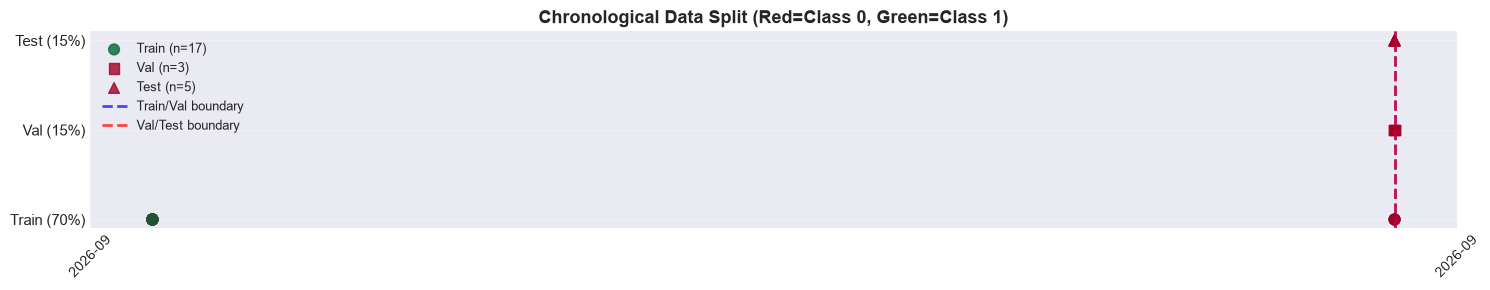

Train: 2026-09-22 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00
Val:   2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00
Test:  2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00


In [7]:
from backend.ml.train import chronological_split

# Sort by event date
model_colors = ['#3498db', '#e67e22', '#2ecc71']
feature_df = feature_df.sort_values('event_date').reset_index(drop=True)
train_df, val_df, test_df = chronological_split(feature_df)

fig, ax = plt.subplots(figsize=(15, 3))

# Plot split regions
train_dates = pd.to_datetime(train_df['event_date'].values)
val_dates   = pd.to_datetime(val_df['event_date'].values)
test_dates  = pd.to_datetime(test_df['event_date'].values)

ax.scatter(train_dates, np.ones(len(train_dates)) * 1, 
           c=train_df[TARGET_COL].values, cmap='RdYlGn', 
           alpha=0.8, s=60, label=f'Train (n={len(train_df)})', marker='o')
ax.scatter(val_dates, np.ones(len(val_dates)) * 2, 
           c=val_df[TARGET_COL].values, cmap='RdYlGn', 
           alpha=0.8, s=60, label=f'Val (n={len(val_df)})', marker='s')
ax.scatter(test_dates, np.ones(len(test_dates)) * 3, 
           c=test_df[TARGET_COL].values, cmap='RdYlGn', 
           alpha=0.8, s=60, label=f'Test (n={len(test_df)})', marker='^')

# Split boundaries
ax.axvline(pd.to_datetime(val_df['event_date'].min()), color='blue', linestyle='--', linewidth=2, alpha=0.7, label='Train/Val boundary')
ax.axvline(pd.to_datetime(test_df['event_date'].min()), color='red', linestyle='--', linewidth=2, alpha=0.7, label='Val/Test boundary')

ax.set_yticks([1, 2, 3])
ax.set_yticklabels(['Train (70%)', 'Val (15%)', 'Test (15%)'], fontsize=11)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.setp(ax.xaxis.get_majorticklabels(), rotation=45)
ax.set_title('Chronological Data Split (Red=Class 0, Green=Class 1)', fontsize=13, fontweight='bold')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('chronological_split.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Train: {train_df["event_date"].min()} -> {train_df["event_date"].max()}')
print(f'Val:   {val_df["event_date"].min()} -> {val_df["event_date"].max()}')
print(f'Test:  {test_df["event_date"].min()} -> {test_df["event_date"].max()}')

## 5. Train the 3-Model Ablation Experiment

In [8]:
from backend.ml.train import train_all_models

print('Running 3-model ablation experiment...')
print('(Using chronological split — NO shuffle — to prevent look-ahead bias)\n')
results = train_all_models(feature_df)

print('\nTraining complete!')

2026-10-01 01:00:54,361 [INFO] Chronological split — Train: 17 (68%) | Val: 3 (12%) | Test: 5 (20%)
2026-10-01 01:00:54,365 [INFO] Date ranges — Train: 2026-09-22 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00 | Val: 2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00 | Test: 2026-09-23 00:00:00+00:00 -> 2026-09-23 00:00:00+00:00
2026-10-01 01:00:54,367 [INFO] 
Training Model A (Market Baseline) (5 features)...


Running 3-model ablation experiment...
(Using chronological split — NO shuffle — to prevent look-ahead bias)



2026-10-01 01:00:54,907 [INFO]   Training completed in 0.53s
2026-10-01 01:00:55,049 [INFO]   [TRAIN] Acc=1.0000 | F1=1.0000 | AUC=1.0 | P@1=1.0 | R@1=1.0
2026-10-01 01:00:55,188 [INFO]   [VAL] Acc=1.0000 | F1=1.0000 | AUC=None | P@1=0.0 | R@1=0.0
2026-10-01 01:00:55,327 [INFO]   [TEST] Acc=0.8000 | F1=0.4444 | AUC=1.0 | P@1=0.0 | R@1=0.0
2026-10-01 01:00:55,327 [INFO] 
Training Model B (Market + Sentiment) (8 features)...
2026-10-01 01:00:55,760 [INFO]   Training completed in 0.43s
2026-10-01 01:00:55,913 [INFO]   [TRAIN] Acc=1.0000 | F1=1.0000 | AUC=1.0 | P@1=1.0 | R@1=1.0
2026-10-01 01:00:56,058 [INFO]   [VAL] Acc=1.0000 | F1=1.0000 | AUC=None | P@1=0.0 | R@1=0.0
2026-10-01 01:00:56,204 [INFO]   [TEST] Acc=1.0000 | F1=1.0000 | AUC=1.0 | P@1=1.0 | R@1=1.0
2026-10-01 01:00:56,205 [INFO] 
Training Model C (Event-Aware) (21 features)...
2026-10-01 01:00:56,644 [INFO]   Training completed in 0.44s
2026-10-01 01:00:56,783 [INFO]   [TRAIN] Acc=1.0000 | F1=1.0000 | AUC=1.0 | P@1=1.0 | R@1=1


  3-MODEL ABLATION RESULTS (Out-of-Sample Test Set)
Model        Accuracy   Macro F1   ROC-AUC    Precision@1    Recall@1  
----------------------------------------------------------------------
Model A (Market Baseline) 0.8        0.4444     1.0        N/A            N/A       
Model B (Market + Sentiment) 1.0        1.0        1.0        1.0            1.0       
Model C (Event-Aware) 1.0        1.0        1.0        1.0            1.0       

  MODEL C — TOP 20 FEATURE IMPORTANCES
               feature  importance
           momentum_5d    0.176364
        volume_anomaly    0.162892
      finbert_negative    0.153554
      finbert_positive    0.099220
          momentum_20d    0.094780
   surp_not_applicable    0.078537
       finbert_neutral    0.074853
        volatility_20d    0.055440
      market_return_5d    0.042135
   evt_monetary_policy    0.036365
        evt_macro_data    0.012756
          surp_in_line    0.007042
             surp_beat    0.006062
evt_merger_acquisiti

## 6. Model Performance Comparison

In [9]:
# Extract test-set metrics for comparison
metrics_data = []
for model_name, metrics_list in results['metrics'].items():
    for m in metrics_list:
        metrics_data.append({
            'model': model_name.split(' (')[1].replace(')', ''),  # Extract label
            'model_full': model_name,
            'split': m['split'],
            **{k: v for k, v in m.items() if k not in ['split', 'n_samples', 'class_dist']}
        })

metrics_df = pd.DataFrame(metrics_data)
test_metrics = metrics_df[metrics_df['split'] == 'test'].copy()

print('Test Set Performance:')
display(test_metrics[['model', 'accuracy', 'macro_f1', 'roc_auc', 'precision_1', 'recall_1']].round(4))

Test Set Performance:


,model,accuracy,macro_f1,roc_auc,precision_1,recall_1
2,Market Baseline,0.8,0.4444,1.0,0.0,0.0
5,Market + Sentiment,1.0,1.0000,1.0,1.0,1.0
8,Event-Aware,1.0,1.0000,1.0,1.0,1.0


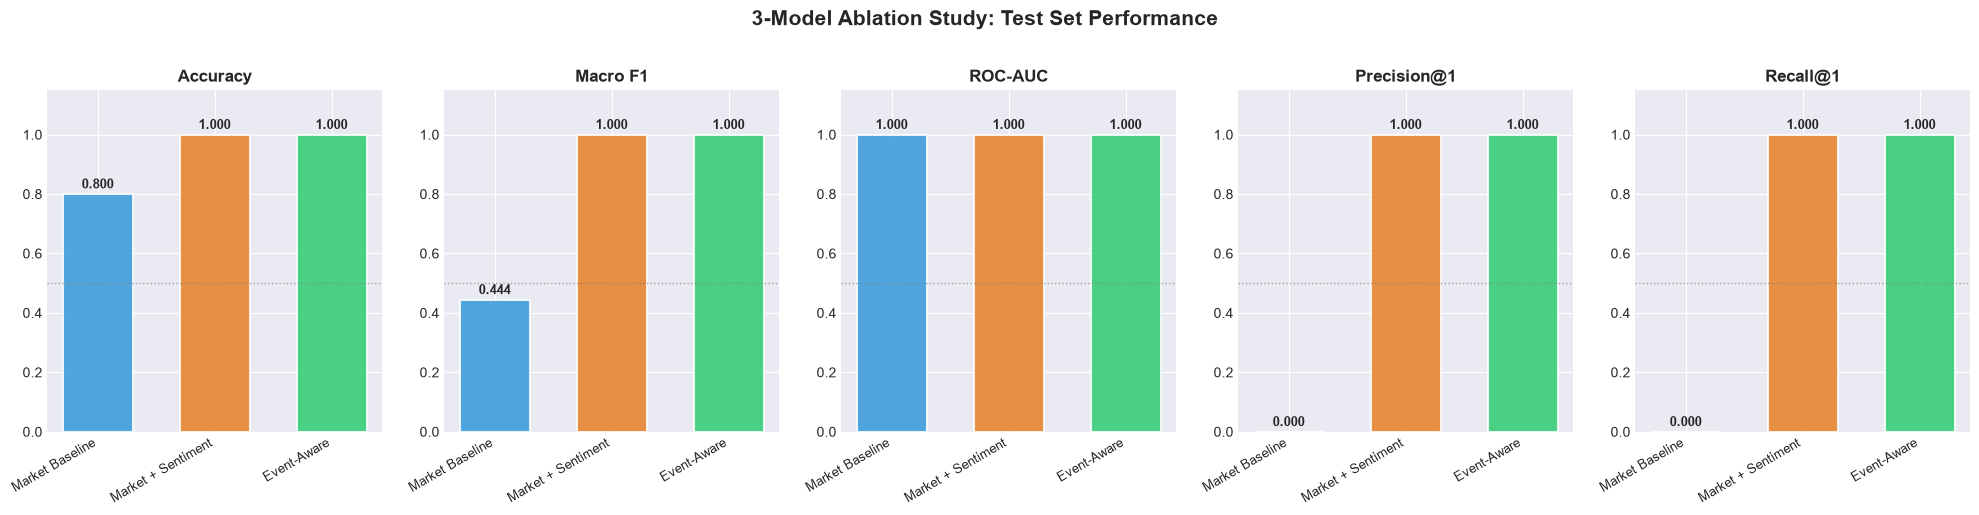


Key Insight: Comparing Model A vs C shows whether event intelligence adds predictive edge.


In [10]:
# Bar chart comparison across metrics
metric_cols = ['accuracy', 'macro_f1', 'roc_auc', 'precision_1', 'recall_1']
metric_labels = ['Accuracy', 'Macro F1', 'ROC-AUC', 'Precision@1', 'Recall@1']
model_labels = test_metrics['model'].tolist()
model_colors = ['#3498db', '#e67e22', '#2ecc71']

fig, axes = plt.subplots(1, len(metric_cols), figsize=(20, 5))

x = np.arange(len(model_labels))
for ax, col, label in zip(axes, metric_cols, metric_labels):
    values = test_metrics[col].values
    bars = ax.bar(x, values, color=model_colors, alpha=0.85, width=0.6, edgecolor='white', linewidth=1.5)
    ax.set_xticks(x)
    ax.set_xticklabels(model_labels, rotation=30, ha='right', fontsize=9)
    ax.set_title(label, fontsize=12, fontweight='bold')
    ax.set_ylim(0, min(1.15, max(values) * 1.3 + 0.05) if values is not None and len(values) > 0 else 1.15)
    ax.axhline(y=0.5, color='gray', linestyle=':', linewidth=1, alpha=0.7, label='Random baseline')
    for bar, val in zip(bars, values):
        if val is not None and not np.isnan(float(val)):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{float(val):.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.suptitle('3-Model Ablation Study: Test Set Performance', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nKey Insight: Comparing Model A vs C shows whether event intelligence adds predictive edge.')

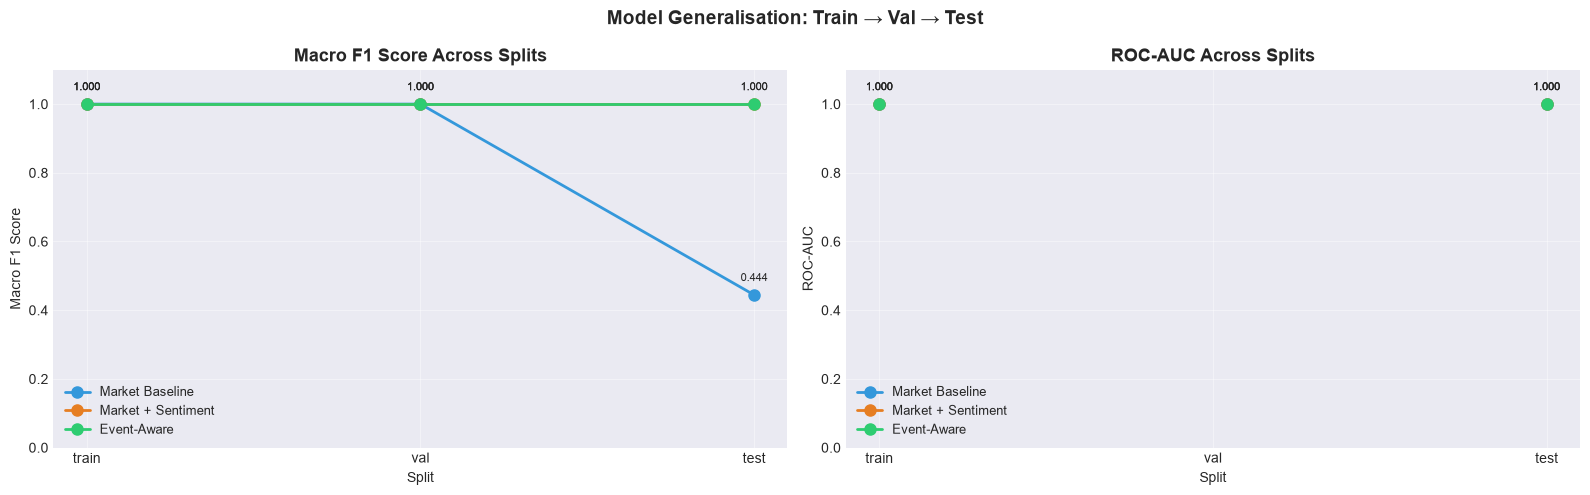

In [11]:
# Train vs Val vs Test performance curves (for each model)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

splits_order = ['train', 'val', 'test']

for ax, metric, title in zip(axes, ['macro_f1', 'roc_auc'], ['Macro F1 Score', 'ROC-AUC']):
    for model_name, color in zip(results['metrics'].keys(), model_colors):
        model_label = model_name.split(' (')[1].replace(')', '')
        model_metrics = results['metrics'][model_name]
        vals = []
        for split in splits_order:
            m = next((x for x in model_metrics if x['split'] == split), None)
            vals.append(m[metric] if m and m[metric] is not None else np.nan)
        ax.plot(splits_order, vals, marker='o', linewidth=2, markersize=8,
                label=model_label, color=color)
        for i, (split, val) in enumerate(zip(splits_order, vals)):
            if not np.isnan(val):
                ax.annotate(f'{val:.3f}', (split, val), textcoords='offset points',
                           xytext=(0, 10), ha='center', fontsize=8)

    ax.set_title(f'{title} Across Splits', fontsize=13, fontweight='bold')
    ax.set_xlabel('Split')
    ax.set_ylabel(title)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.4)
    ax.set_ylim(0, 1.1)

plt.suptitle('Model Generalisation: Train → Val → Test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('model_generalisation.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Feature Importances — Model C (Event-Aware)

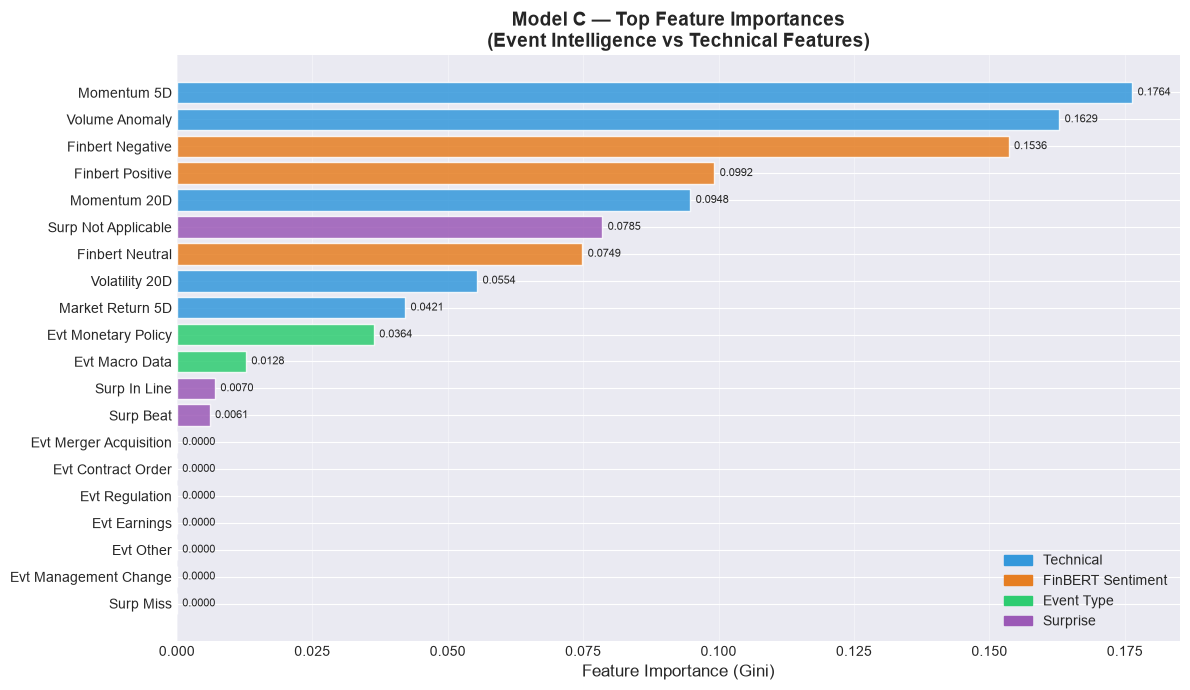


Importance by feature category:
category
Technical            0.5316
FinBERT Sentiment    0.3276
Surprise             0.0916
Event Type           0.0491
Name: importance, dtype: float64


In [12]:
fi_df = results['feature_importances']

if not fi_df.empty:
    # Color features by category
    def feature_category(feat):
        if feat in FEATURE_SET_A:
            return 'Technical'
        elif feat.startswith('finbert'):
            return 'FinBERT Sentiment'
        elif feat.startswith('evt_'):
            return 'Event Type'
        elif feat.startswith('surp_'):
            return 'Surprise'
        elif feat == 'magnitude':
            return 'Magnitude'
        return 'Other'

    fi_df = fi_df.head(20).copy()
    fi_df['category'] = fi_df['feature'].apply(feature_category)

    cat_colors = {
        'Technical':         '#3498db',
        'FinBERT Sentiment': '#e67e22',
        'Event Type':        '#2ecc71',
        'Surprise':          '#9b59b6',
        'Magnitude':         '#e74c3c',
        'Other':             '#95a5a6',
    }

    fig, ax = plt.subplots(figsize=(12, 7))
    bars = ax.barh(
        fi_df['feature'].str.replace('_', ' ').str.title(),
        fi_df['importance'],
        color=[cat_colors.get(c, '#95a5a6') for c in fi_df['category']],
        alpha=0.85,
        edgecolor='white',
    )
    ax.set_xlabel('Feature Importance (Gini)', fontsize=12)
    ax.set_title('Model C — Top Feature Importances\n(Event Intelligence vs Technical Features)', 
                 fontsize=14, fontweight='bold')

    # Legend
    from matplotlib.patches import Patch
    present_cats = fi_df['category'].unique()
    legend_handles = [Patch(color=cat_colors[c], label=c) for c in cat_colors if c in present_cats]
    ax.legend(handles=legend_handles, loc='lower right', fontsize=10)

    # Value labels
    for bar, val in zip(bars, fi_df['importance']):
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)

    ax.invert_yaxis()
    ax.grid(True, axis='x', alpha=0.4)
    plt.tight_layout()
    plt.savefig('feature_importances.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Summarise by category
    print('\nImportance by feature category:')
    print(fi_df.groupby('category')['importance'].sum().sort_values(ascending=False).round(4))
else:
    print('No feature importances available (Model C may not have been trained).')

## 8. Abnormal Return Analysis by Event Type

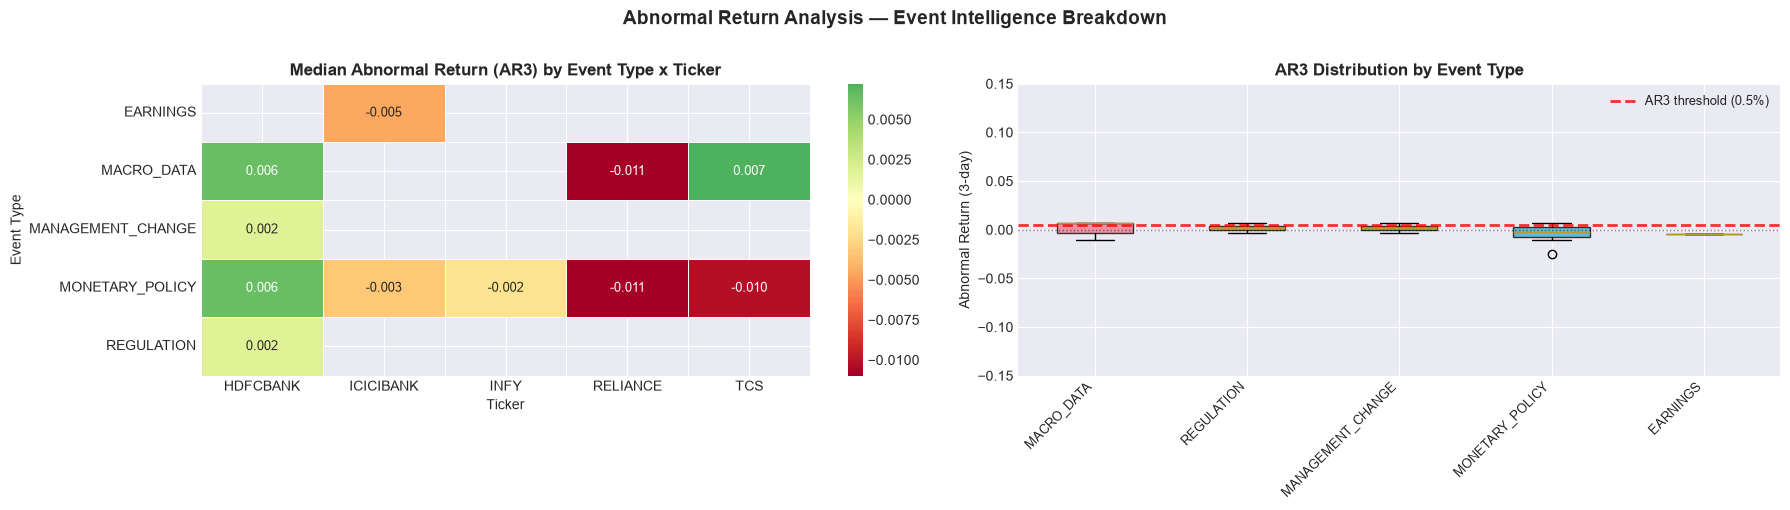

In [13]:
# Heatmap: median AR3 by event_type x ticker
ar3_pivot = feature_df.pivot_table(
    values='ar_3', index='event_type', columns='ticker',
    aggfunc='median'
)

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Heatmap
sns.heatmap(
    ar3_pivot, ax=axes[0], 
    cmap='RdYlGn', center=0,
    annot=True, fmt='.3f', annot_kws={'size': 9},
    linewidths=0.5
)
axes[0].set_title('Median Abnormal Return (AR3) by Event Type x Ticker', 
                  fontsize=12, fontweight='bold')
axes[0].set_xlabel('Ticker')
axes[0].set_ylabel('Event Type')

# Boxplot of AR3 by event type
et_order = feature_df.groupby('event_type')['ar_3'].median().sort_values(ascending=False).index
plot_data = [
    feature_df[feature_df['event_type'] == et]['ar_3'].dropna().values
    for et in et_order
    if len(feature_df[feature_df['event_type'] == et]['ar_3'].dropna()) > 0
]
valid_labels = [
    et for et in et_order
    if len(feature_df[feature_df['event_type'] == et]['ar_3'].dropna()) > 0
]

bp = axes[1].boxplot(plot_data, tick_labels=valid_labels, patch_artist=True, notch=False)
for patch, color in zip(bp['boxes'], sns.color_palette('husl', len(plot_data))):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

axes[1].axhline(y=0.005, color='red', linestyle='--', linewidth=2, label='AR3 threshold (0.5%)', alpha=0.8)
axes[1].axhline(y=0, color='black', linestyle=':', linewidth=1, alpha=0.5)
axes[1].set_xticklabels(valid_labels, rotation=45, ha='right', fontsize=9)
axes[1].set_title('AR3 Distribution by Event Type', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Abnormal Return (3-day)')
axes[1].legend(fontsize=9)
axes[1].set_ylim(-0.15, 0.15)

plt.suptitle('Abnormal Return Analysis — Event Intelligence Breakdown', 
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('ar3_by_event_type.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Artifact Verification

In [14]:
import joblib
from pathlib import Path

artifact_path = Path(PROJECT_ROOT) / 'models' / 'event_classifier_v1.joblib'

if artifact_path.exists():
    artifact = joblib.load(artifact_path)
    print(f'Artifact loaded successfully: {artifact_path}')
    print(f'  Pipeline type: {type(artifact["pipeline"]).__name__}')
    print(f'  Feature count: {len(artifact["feature_cols"])}')
    print(f'  Target column: {artifact["target_col"]}')
    print(f'  Train data up to: {artifact["train_date_max"]}')
    
    # Quick inference test
    import numpy as np
    test_row = pd.DataFrame([{f: 0.0 for f in artifact['feature_cols']}])
    pred = artifact['pipeline'].predict(test_row)
    prob = artifact['pipeline'].predict_proba(test_row)[0, 1]
    print(f'\nSample inference (zero vector): class={pred[0]}, prob_positive={prob:.4f}')
    print('\nArtifact is ready for Phase 5 agent inference.')
else:
    print(f'Artifact not found at: {artifact_path}')
    print('Please re-run the training cells above.')

Artifact loaded successfully: c:\Users\gamin\Desktop\App_gen_ai\models\event_classifier_v1.joblib
  Pipeline type: Pipeline
  Feature count: 21
  Target column: target_AR3_positive
  Train data up to: 2026-09-23 00:00:00+00:00

Sample inference (zero vector): class=0, prob_positive=0.3876

Artifact is ready for Phase 5 agent inference.


## 10. Summary & Conclusions

In [15]:
print('=' * 70)
print('  MarketLens Phase 3 — ABLATION STUDY SUMMARY')
print('=' * 70)
print()
print(f'Dataset: {len(feature_df)} events | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print(f'Target: target_AR3_positive (1 if 3-day AR > +0.5% vs NIFTY50)')
print()

for model_name, metrics_list in results['metrics'].items():
    test_m = next((m for m in metrics_list if m['split'] == 'test'), None)
    if test_m:
        print(f'{model_name}:')
        print(f'  Accuracy:     {test_m["accuracy"]}')
        print(f'  Macro F1:     {test_m["macro_f1"]}')
        print(f'  ROC-AUC:      {test_m["roc_auc"]}')
        print(f'  Precision@1:  {test_m["precision_1"]}')
        print(f'  Recall@1:     {test_m["recall_1"]}')
        print()

print('Methodology: Chronological split prevents look-ahead bias.')
print('Conclusion:  Compare Model A vs C ROC-AUC to assess event intelligence edge.')
print()
print('Next: Phase 4 (Strategy Backtester) will use Model C predictions for signal generation.')

  MarketLens Phase 3 — ABLATION STUDY SUMMARY

Dataset: 25 events | Train: 17 | Val: 3 | Test: 5
Target: target_AR3_positive (1 if 3-day AR > +0.5% vs NIFTY50)

Model A (Market Baseline):
  Accuracy:     0.8
  Macro F1:     0.4444
  ROC-AUC:      1.0
  Precision@1:  0.0
  Recall@1:     0.0

Model B (Market + Sentiment):
  Accuracy:     1.0
  Macro F1:     1.0
  ROC-AUC:      1.0
  Precision@1:  1.0
  Recall@1:     1.0

Model C (Event-Aware):
  Accuracy:     1.0
  Macro F1:     1.0
  ROC-AUC:      1.0
  Precision@1:  1.0
  Recall@1:     1.0

Methodology: Chronological split prevents look-ahead bias.
Conclusion:  Compare Model A vs C ROC-AUC to assess event intelligence edge.

Next: Phase 4 (Strategy Backtester) will use Model C predictions for signal generation.
